# 3. Synthetic DiD: high vs low AI-exposure industries

**Question:** Did the 20 most AI-exposed industries fall relative to 43 low-exposure industries after 2022?

**How to use:** Run All. It shows the saved results in seconds. To recompute from the data, set `RUN = True` (about 3 minutes; needs the raw data in `data/raw/`, which isn't in the public repo; see the README).

In [1]:
from _nb import *

RUN = False
if RUN:
    run("sdid_industry")


## How it works

- **Synthetic DiD** (Arkhangelsky et al. 2021): weights control industries *and* baseline years so the comparison
  is fair, then takes a difference-in-differences. Pooling many treated units averages out noise.
- **Two baselines:** late 2021 (the plan) and 2019 (pre-pandemic). See "what it means".
- **Checks:** the middle-exposure group (dose-response), the dot-com bust (no AI), and a fake 2016 shock.

## Results

In [2]:
r = results("sdid_industry")
rows = {"2019 baseline (primary)": "2022_high_pre_ends_2019", "Late-2021 baseline": "2022_high",
        "Middle exposure, 2019 baseline": "2022_middle_pre_ends_2019", "Dot-com bust (no AI)": "dotcom_high",
        "Placebo: fake 2016 shock": "placebo_2016_high"}
pd.DataFrame({k: {"effect": pct(r[v]["tau"]), "95% CI": ci(r[v].get("ci95"))} for k, v in rows.items()}).T

,effect,95% CI
2019 baseline (primary),+0.7%,"[-2.9, +4.3]"
Late-2021 baseline,-3.9%,"[-6.0, -1.7]"
"Middle exposure, 2019 baseline",-1.0%,"[-4.8, +2.8]"
Dot-com bust (no AI),-3.2%,"[-7.0, +0.6]"
Placebo: fake 2016 shock,+0.7%,"[-2.0, +3.5]"


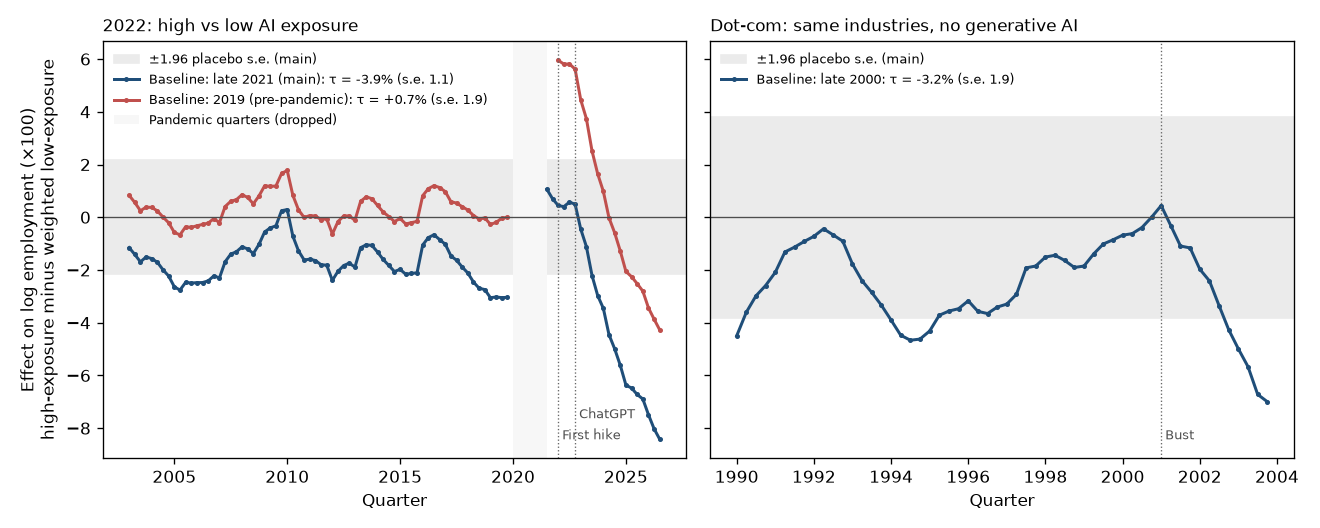

In [3]:
figure("fig_sdid_industry")

## What it means

**No AI-specific decline.** The late-2021 baseline gives −3.9%, but the method put 81% of its baseline weight on
2021-Q4, the peak of the pandemic boom, so it measured the boom unwinding. Against 2019 it's +0.7%, not significant.
The high-exposure group (+0.7%) did no worse than the middle group (−1.0%), so there is no dose-response, and the dot-com bust produced a similar drop (−3.2%) with no
AI. **Decision that followed:** 2019 is the primary baseline for every analysis.

---
Code: `scripts/sdid_industry.py` · All results: `docs/SCORECARD.md` · Every decision: `docs/DECISIONS.md` · The whole story: `README.md`